# Weekly Confirmed COVID-19 Cases: Country, Regional and Global Analysis

This notebook explores the Our World in Data (OWID) weekly confirmed COVID-19 case series. It covers 249 locations (countries, regions, income groups and world totals) from January 2020 to October 2026.

**Read this first.** The column called `Weekly cases` is not a count for one day. For each date, it holds the number of confirmed cases in the seven days ending on that date. That is a rolling seven-day total. Adding the daily rows together therefore counts each case about seven times. Every total in this notebook divides the sum by 7 to correct for this. Section 0 shows the check that supports this reading.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
sns.set_palette("colorblind")
FIG = "figures/"


## 0. Loading and checking the data

I rename the columns to short lowercase names and check for duplicates, negative values and the date range. I also test the seven-day reading against a known total: the World series summed and divided by 7 should be close to the cumulative confirmed count that WHO has published.

In [2]:
raw = pd.read_csv("data/raw/weekly-covid-cases.csv", parse_dates=["Day"])
w = raw.rename(columns={"Entity": "entity", "Code": "code", "Day": "date", "Weekly cases": "weekly"})

AGGREGATES = [
    "World", "Africa", "Asia", "Europe", "North America", "South America", "Oceania",
    "European Union (27)", "High-income countries", "Upper-middle-income countries",
    "Lower-middle-income countries", "Low-income countries", "World excl. China",
    "World excl. China and South Korea", "World excl. China, South Korea, Japan and Singapore",
    "Asia excl. China",
]
w["is_country"] = ~w["entity"].isin(AGGREGATES)
w["daily_avg"] = w["weekly"] / 7          # average new cases per day over the 7-day window

print("Rows:", f"{len(w):,}")
print("Locations:", w["entity"].nunique(), "| countries:", w.loc[w.is_country, "entity"].nunique())
print("Date range:", w["date"].min().date(), "to", w["date"].max().date())
print("Duplicate entity-date pairs:", w.duplicated(["entity", "date"]).sum())
print("Negative values:", (w["weekly"] < 0).sum())
print("Missing codes (aggregates have none):", w["code"].isna().sum())

world = w[w["entity"] == "World"].set_index("date").sort_index()
countries = w[w["is_country"]].copy()

# Check the seven-day reading against a known total
world_sum = world["weekly"].sum()
print(f"\nWorld sum of all rows:        {world_sum:,.0f}")
print(f"World sum divided by 7:       {world_sum/7:,.0f}")
print("Reading: about 779 million cumulative confirmed cases, which matches the scale WHO has reported.")


Rows: 609,658
Locations: 249 | countries: 233
Date range: 2020-01-09 to 2026-10-11
Duplicate entity-date pairs: 0
Negative values: 0
Missing codes (aggregates have none): 9872



World sum of all rows:        5,456,170,211
World sum divided by 7:       779,452,887
Reading: about 779 million cumulative confirmed cases, which matches the scale WHO has reported.


## 1. How has the global weekly case count changed over time?

The first question is the overall shape of the pandemic in this data. I plot the global daily average, which is the seven-day total divided by 7, and mark the highest point.

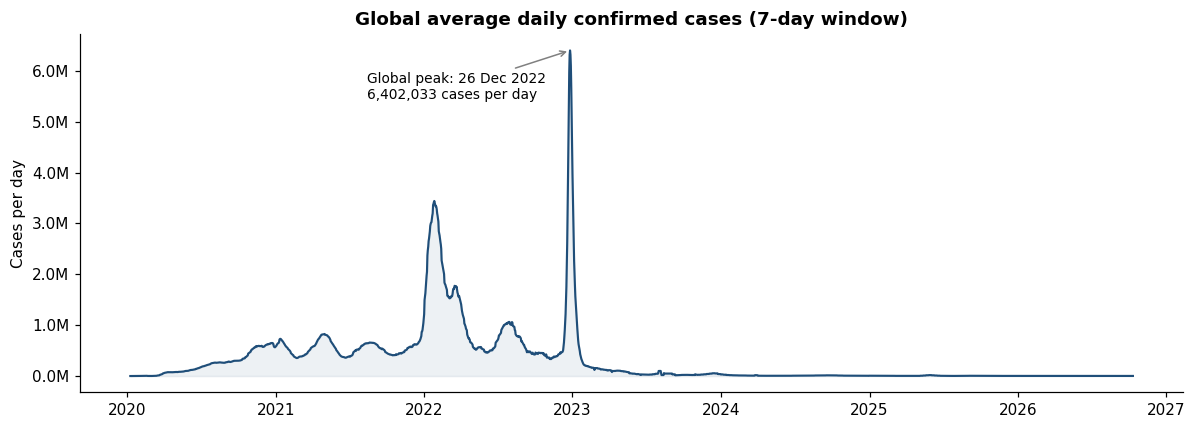

Global peak date: 2022-12-26 with about 6,402,033 cases per day.


In [3]:
s = world["daily_avg"]
peak_date, peak_val = s.idxmax(), s.max()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(s.index, s.values, color="#1f4e79", linewidth=1.4)
ax.fill_between(s.index, s.values, color="#1f4e79", alpha=0.08)
ax.annotate(f"Global peak: {peak_date:%d %b %Y}\n{peak_val:,.0f} cases per day",
            xy=(peak_date, peak_val), xytext=(peak_date - pd.Timedelta(days=500), peak_val * 0.85),
            arrowprops=dict(arrowstyle="->", color="grey"), fontsize=9)
ax.set_title("Global average daily confirmed cases (7-day window)")
ax.set_ylabel("Cases per day")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.tight_layout(); plt.savefig(FIG + "01_global_trend.png"); plt.show()

print(f"Global peak date: {peak_date.date()} with about {peak_val:,.0f} cases per day.")


## 2. How many cases were recorded each year?

I divide each year's summed rows by 7 to get an estimate of confirmed cases in that year. The result shows which years carried most of the burden.

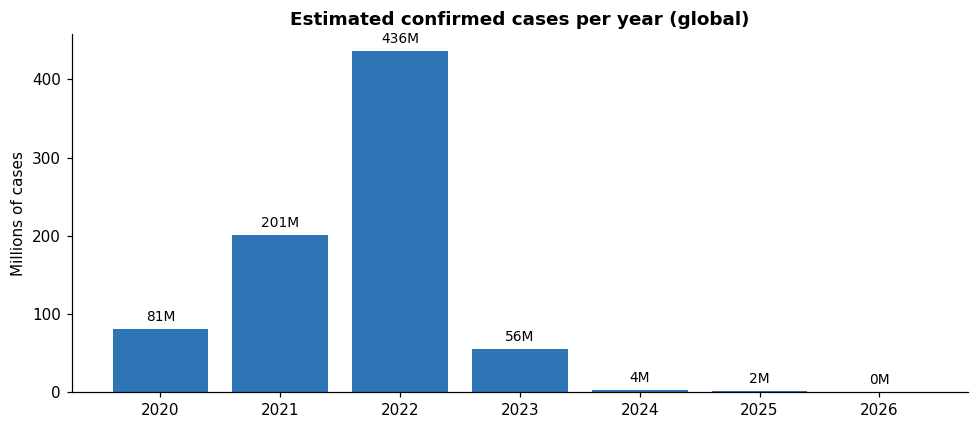

,estimated_cases,share_of_total
date,,
2020,80643095,0.103
2021,201351384,0.258
2022,436082810,0.559
2023,55705121,0.071
2024,3533880,0.005
2025,1707503,0.002
2026,429094,0.001


In [4]:
yearly = (world["weekly"].groupby(world.index.year).sum() / 7).rename("cases")
yearly_m = yearly / 1e6

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(yearly_m.index.astype(str), yearly_m.values, color="#2e75b6")
for b, v in zip(bars, yearly_m.values):
    ax.text(b.get_x() + b.get_width()/2, v + 10, f"{v:,.0f}M", ha="center", fontsize=9)
ax.set_title("Estimated confirmed cases per year (global)")
ax.set_ylabel("Millions of cases")
plt.tight_layout(); plt.savefig(FIG + "02_yearly_totals.png"); plt.show()

yearly_table = pd.DataFrame({"estimated_cases": yearly.round(0).astype("int64"),
                             "share_of_total": (yearly / yearly.sum()).round(3)})
yearly_table


## 3. Which countries recorded the most confirmed cases?

I sum each country's rows, divide by 7, and rank the countries. Counts reflect testing capacity and reporting as well as true infection levels, so large numbers do not automatically mean a bigger outbreak.

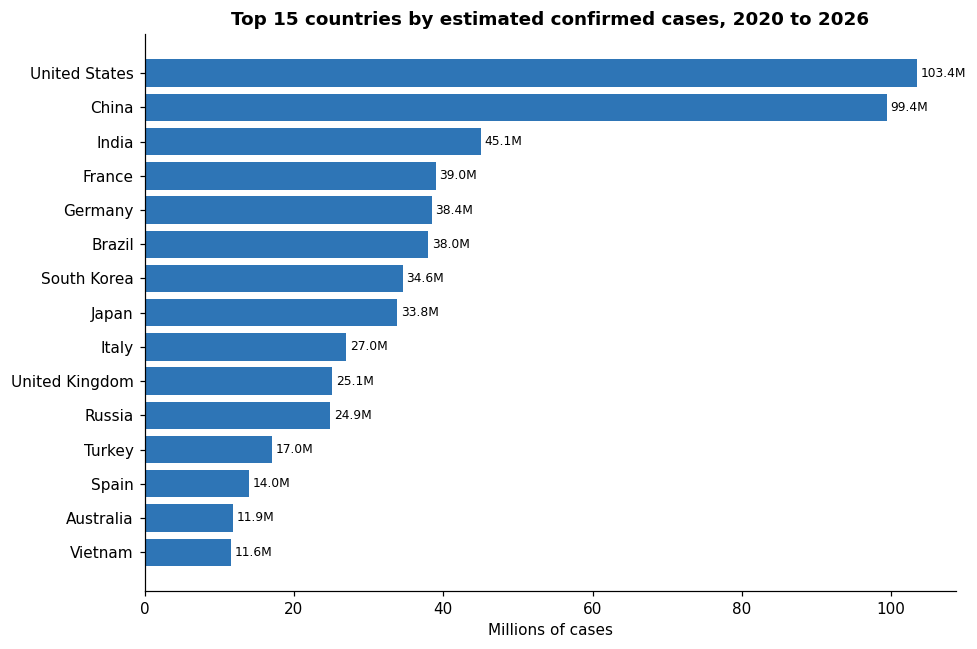

,estimated_cases
entity,
United States,103436829
China,99381759
India,45056286
France,38997490
Germany,38437755
Brazil,38026093
South Korea,34571873
Japan,33803572
Italy,26969918


In [5]:
totals = (countries.groupby("entity")["weekly"].sum() / 7).sort_values(ascending=False)
top15 = totals.head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15.index[::-1], top15.values[::-1] / 1e6, color="#2e75b6")
for i, v in enumerate(top15.values[::-1] / 1e6):
    ax.text(v + 0.5, i, f"{v:,.1f}M", va="center", fontsize=8)
ax.set_title("Top 15 countries by estimated confirmed cases, 2020 to 2026")
ax.set_xlabel("Millions of cases")
plt.tight_layout(); plt.savefig(FIG + "03_top15_countries.png"); plt.show()

top15.to_frame("estimated_cases").astype(int)


## 4. Did different continents experience waves at different times?

I compare the daily averages for the six continental aggregates. The log scale shows the smaller waves as clearly as the large ones.

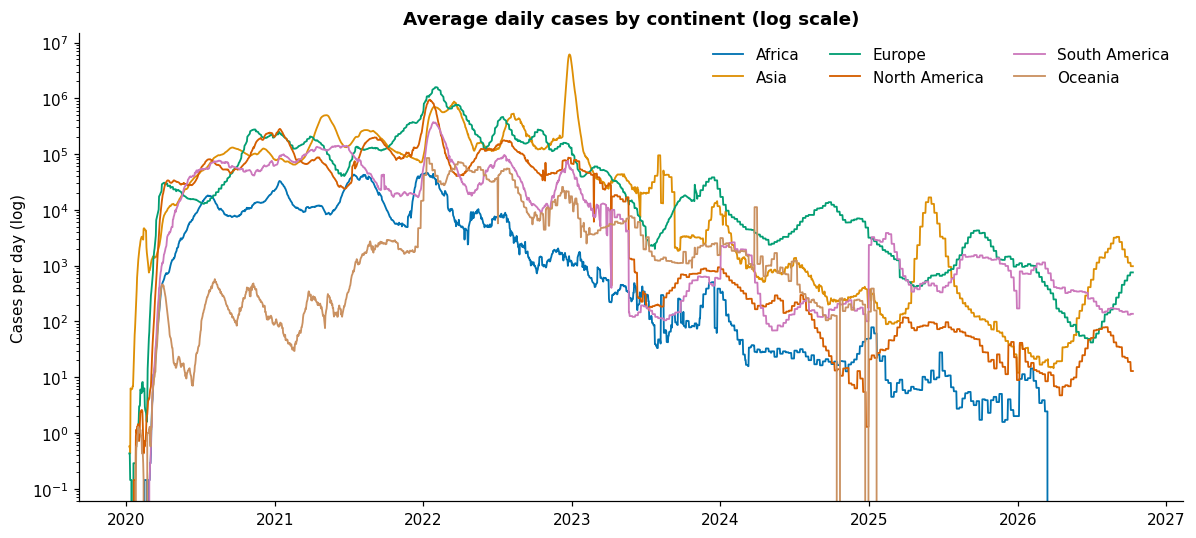

In [6]:
continents = ["Africa", "Asia", "Europe", "North America", "South America", "Oceania"]
cont = w[w["entity"].isin(continents)].pivot(index="date", columns="entity", values="daily_avg")

fig, ax = plt.subplots(figsize=(11, 5))
for c in continents:
    ax.plot(cont.index, cont[c], label=c, linewidth=1.2)
ax.set_yscale("log")
ax.set_title("Average daily cases by continent (log scale)")
ax.set_ylabel("Cases per day (log)")
ax.legend(ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG + "04_continent_waves.png"); plt.show()


## 5. Is Africa's share of recorded cases growing or shrinking?

For each year, I compare Africa's estimated total with the world total. A low share here can reflect lower testing or reporting as much as lower infection. This dataset cannot separate those two explanations.

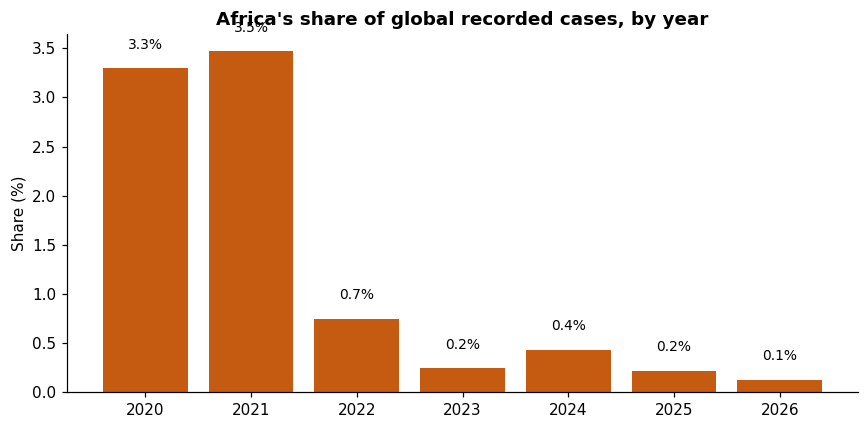

,africa_share
date,
2020,0.033
2021,0.035
2022,0.007
2023,0.002
2024,0.004
2025,0.002
2026,0.001


In [7]:
afr = w[w["entity"] == "Africa"].set_index("date")["weekly"]
share = (afr.groupby(afr.index.year).sum() / world["weekly"].groupby(world.index.year).sum()).dropna()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(share.index.astype(str), share.values * 100, color="#c55a11")
for x, v in zip(share.index.astype(str), share.values * 100):
    ax.text(x, v + 0.2, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_title("Africa's share of global recorded cases, by year")
ax.set_ylabel("Share (%)")
plt.tight_layout(); plt.savefig(FIG + "05_africa_share.png"); plt.show()
share.round(3).to_frame("africa_share")


## 6. When did each country reach its highest daily count?

For every country, I record the date and size of its highest daily average. The scatter plot shows whether peaks cluster in time, which would point to variants or shared policy moments.

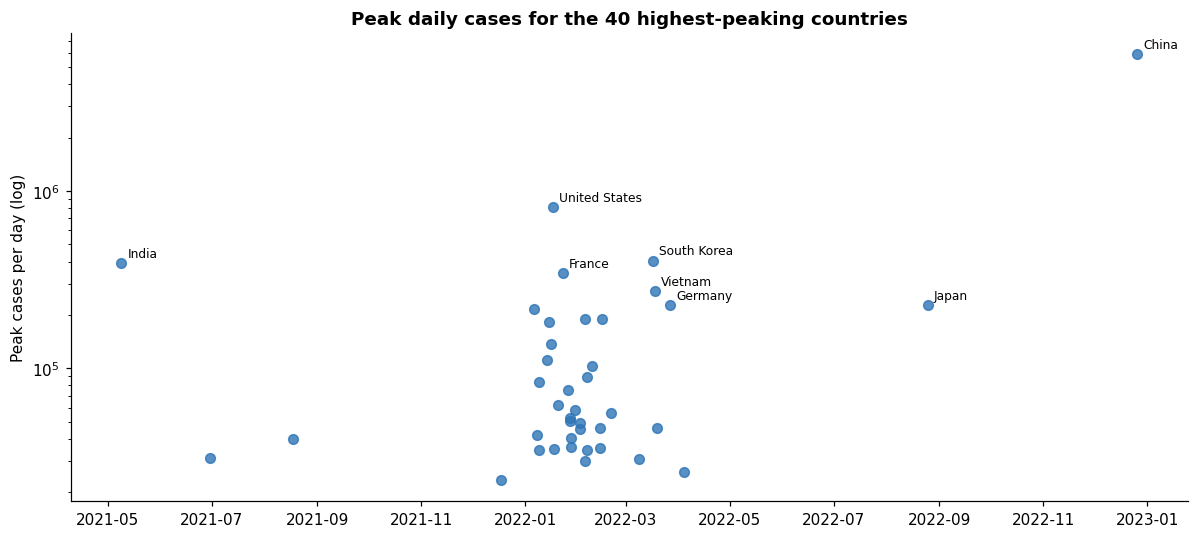

,entity,peak_date,peak_daily_cases
0,China,2022-12-26,5.882129e+06
1,United States,2022-01-17,8.097353e+05
2,South Korea,2022-03-17,4.049996e+05
3,India,2021-05-09,3.912796e+05
4,France,2022-01-23,3.452919e+05
5,Vietnam,2022-03-18,2.740253e+05
6,Japan,2022-08-25,2.278367e+05
7,Germany,2022-03-27,2.269844e+05
8,United Kingdom,2022-01-06,2.146903e+05
9,Russia,2022-02-15,1.904186e+05


In [8]:
peaks = (countries.loc[countries.groupby("entity")["daily_avg"].idxmax(), ["entity", "date", "daily_avg"]]
         .rename(columns={"date": "peak_date", "daily_avg": "peak_daily_cases"})
         .sort_values("peak_daily_cases", ascending=False)
         .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(11, 5))
top = peaks.head(40)
ax.scatter(top["peak_date"], top["peak_daily_cases"], s=40, color="#2e75b6", alpha=0.8)
for _, r in top.head(8).iterrows():
    ax.annotate(r["entity"], (r["peak_date"], r["peak_daily_cases"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set_yscale("log")
ax.set_title("Peak daily cases for the 40 highest-peaking countries")
ax.set_ylabel("Peak cases per day (log)")
plt.tight_layout(); plt.savefig(FIG + "06_peak_timing.png"); plt.show()

peaks.head(10)


## 7. How do Nigeria's waves compare with those of other African countries?

I compare Nigeria with South Africa, Kenya, Ghana and Egypt. Each series is shown on a log scale, so the timing of waves is clear, but the scale of each country's outbreak is not directly comparable without population data, which this file does not include.

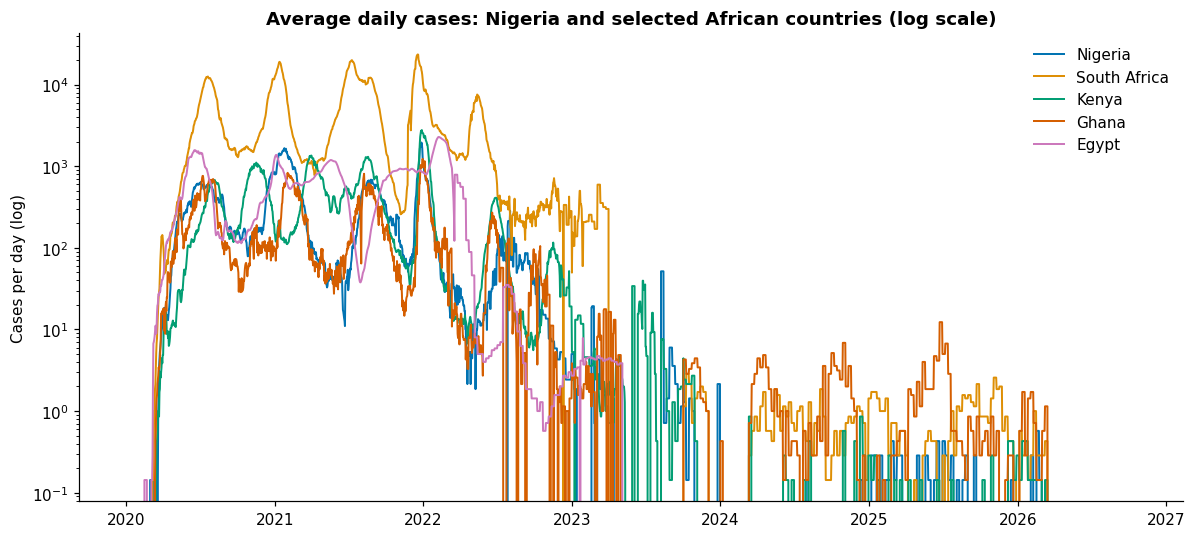

,country,peak_date,peak_daily_cases,estimated_total
0,Nigeria,2021-12-27,1953,267237
1,South Africa,2021-12-18,23437,4073188
2,Kenya,2021-12-28,2775,344170
3,Ghana,2021-12-30,1231,172843
4,Egypt,2022-02-08,2287,516023


In [9]:
compare = ["Nigeria", "South Africa", "Kenya", "Ghana", "Egypt"]
cc = countries[countries["entity"].isin(compare)].pivot(index="date", columns="entity", values="daily_avg")

fig, ax = plt.subplots(figsize=(11, 5))
for c in compare:
    ax.plot(cc.index, cc[c], label=c, linewidth=1.3)
ax.set_yscale("log")
ax.set_title("Average daily cases: Nigeria and selected African countries (log scale)")
ax.set_ylabel("Cases per day (log)")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + "07_nigeria_vs_africa.png"); plt.show()

rows = []
for c in compare:
    s_c = cc[c].dropna()
    rows.append({"country": c, "peak_date": s_c.idxmax().date(), "peak_daily_cases": round(s_c.max()),
                 "estimated_total": int(countries[countries.entity == c]["weekly"].sum() / 7)})
pd.DataFrame(rows)


## 8. Which months of the year carry the most cases?

I build a heatmap of the average daily global cases for each year and month. Seasonal patterns can look like waves in some years and not others, so the heatmap helps tell them apart.

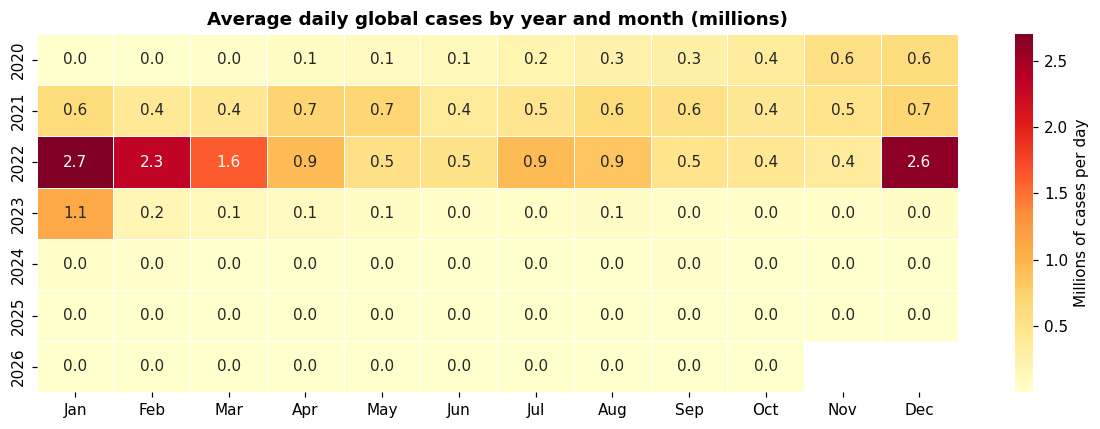

In [10]:
hm = world["daily_avg"].resample("MS").mean().to_frame("v")
hm["year"], hm["month"] = hm.index.year, hm.index.month
pivot = hm.pivot(index="year", columns="month", values="v")
pivot.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(pivot / 1e6, cmap="YlOrRd", annot=True, fmt=".1f", linewidths=0.4,
            cbar_kws={"label": "Millions of cases per day"}, ax=ax)
ax.set_title("Average daily global cases by year and month (millions)")
ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG + "08_month_year_heatmap.png"); plt.show()


## 9. How many distinct waves did each large country experience?

I smooth each country's series over 28 days, then count the peaks. A peak only counts if it rises well above the surrounding values and occurs at least 90 days after the previous one. These thresholds are judgement calls, so treat the counts as a rough guide.

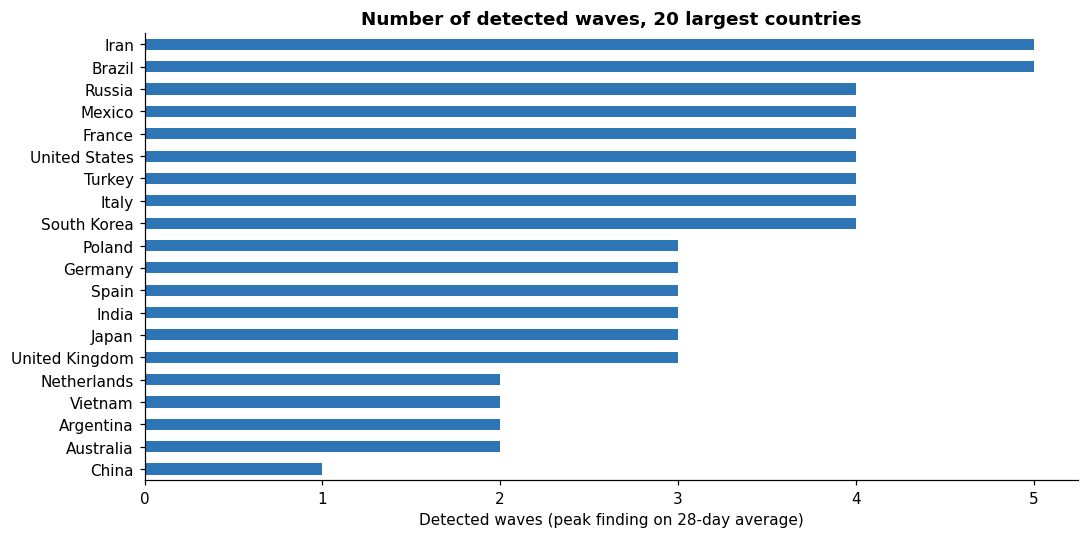

country,United States,China,India,France,Germany,Brazil,South Korea,Japan,Italy,United Kingdom,Russia,Turkey,Spain,Australia,Vietnam,Argentina,Netherlands,Mexico,Iran,Poland
waves_detected,4,1,3,4,3,5,4,3,4,3,4,4,3,2,2,2,2,4,5,3


In [11]:
big = totals.head(20).index
rows = []
for c in big:
    s_c = countries[countries.entity == c].set_index("date")["daily_avg"].sort_index()
    sm = s_c.rolling(28, center=True, min_periods=7).mean().fillna(0)
    idx, _ = find_peaks(sm.values, prominence=sm.max() * 0.10, distance=90)
    rows.append({"country": c, "waves_detected": len(idx)})
waves = pd.DataFrame(rows).set_index("country")

fig, ax = plt.subplots(figsize=(10, 5))
waves.sort_values("waves_detected")["waves_detected"].plot.barh(ax=ax, color="#2e75b6")
ax.set_title("Number of detected waves, 20 largest countries")
ax.set_xlabel("Detected waves (peak finding on 28-day average)")
ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG + "09_wave_counts.png"); plt.show()
waves.T


## 10. When did global cases grow fastest in a single week?

I measure the week-on-week change in the global daily average. I only count weeks where the starting level was at least 1,000 cases per day, because small bases produce misleading percentages.

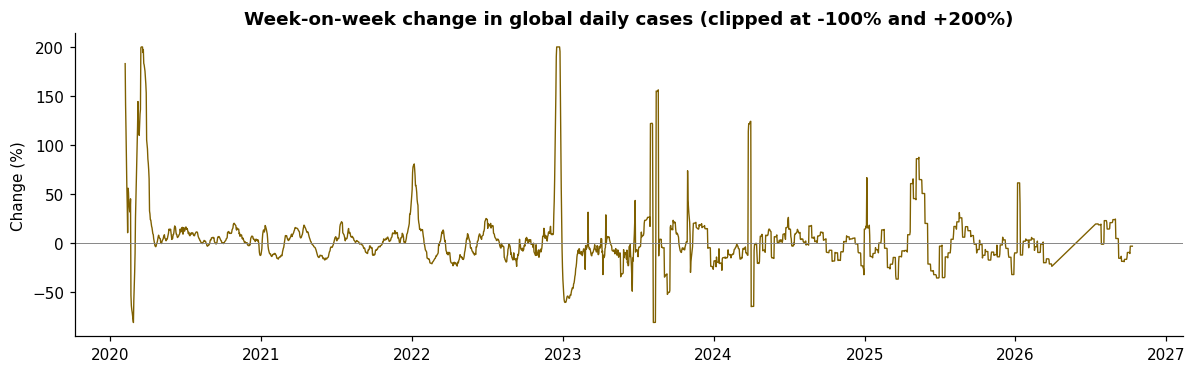

,week_on_week_growth
date,
2022-12-22,282.1%
2022-12-21,269.7%
2022-12-23,264.6%
2022-12-20,256.6%
2022-12-24,241.0%
2022-12-19,239.4%
2022-12-18,224.5%
2020-03-18,215.4%
2020-03-17,206.0%


In [12]:
base = world["daily_avg"]
growth = (base / base.shift(7) - 1)[base.shift(7) >= 1000]
top_growth = growth.sort_values(ascending=False).head(10).to_frame("week_on_week_growth")
top_growth["week_on_week_growth"] = (top_growth["week_on_week_growth"] * 100).round(1).astype(str) + "%"

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(growth.index, (growth.clip(-1, 2) * 100), linewidth=0.9, color="#7f6000")
ax.axhline(0, color="grey", linewidth=0.6)
ax.set_title("Week-on-week change in global daily cases (clipped at -100% and +200%)")
ax.set_ylabel("Change (%)")
plt.tight_layout(); plt.savefig(FIG + "10_growth_rate.png"); plt.show()

top_growth


## 11. Which countries report in weekly batches and which report daily?

If a country reports once a week, its rolling value stays the same for several days in a row. I measure this only on days with at least one case, so long zero stretches do not inflate the result. Countries with at least 60 such days are included.

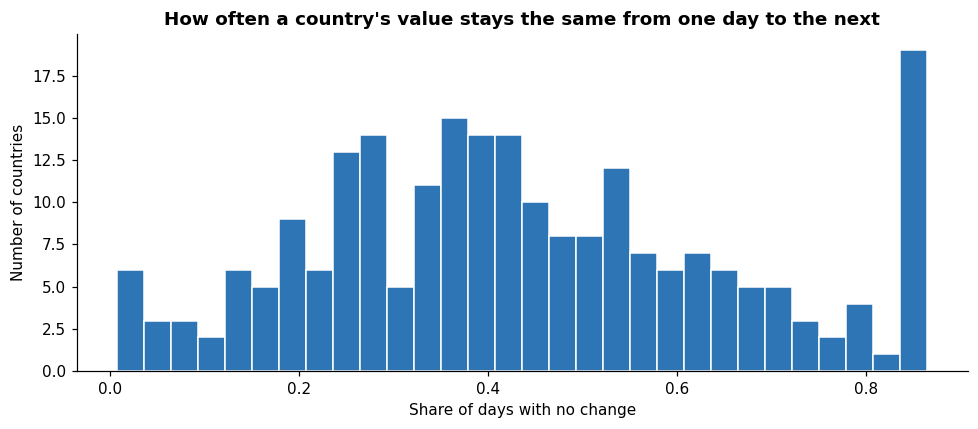

Countries (with 60+ non-zero days) where the value is unchanged more than half the time: 83 of 229


,share_unchanged_day_to_day
entity,
Iceland,0.87
Malta,0.87
Latvia,0.86
Kyrgyzstan,0.86
Slovenia,0.86
Ukraine,0.86
Nicaragua,0.86
Netherlands,0.86
North Macedonia,0.86


In [13]:
nz = countries[countries.weekly > 0].sort_values(["entity", "date"])
stab = (nz.groupby("entity")["weekly"]
        .apply(lambda s: (s.diff() == 0).mean()).rename("share_unchanged_day_to_day"))
stab = stab[nz.groupby("entity").size() >= 60]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(stab.values, bins=30, color="#2e75b6", edgecolor="white")
ax.set_title("How often a country's value stays the same from one day to the next")
ax.set_xlabel("Share of days with no change")
ax.set_ylabel("Number of countries")
plt.tight_layout(); plt.savefig(FIG + "11_reporting_pattern.png"); plt.show()

print("Countries (with 60+ non-zero days) where the value is unchanged more than half the time:", (stab > 0.5).sum(), "of", len(stab))
stab.sort_values(ascending=False).head(10).round(2).to_frame()


## 12. Which countries have stopped reporting?

For each country, I find the last date with a non-zero count. Countries whose series stop early may have ended reporting, and their totals should be read with that in mind.

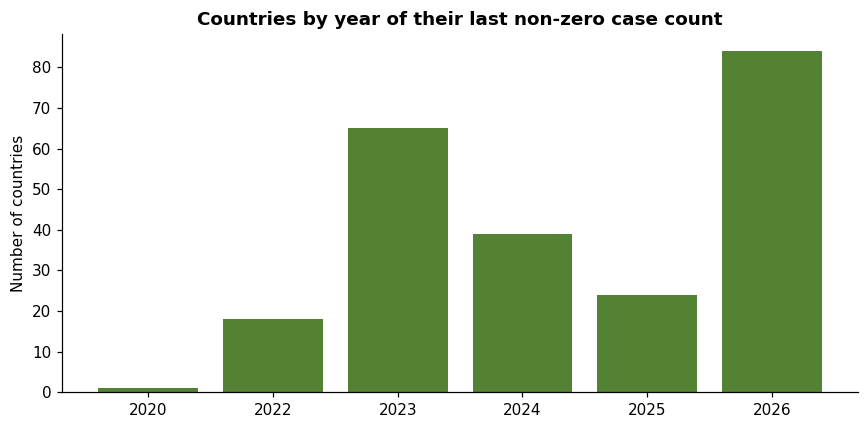

147 countries have no non-zero count in 2026. Earliest stops:


,last_reported_case_date
entity,
Vatican,2020-10-22
Tajikistan,2022-02-25
Faroe Islands,2022-03-08
Greenland,2022-03-31
Djibouti,2022-06-15
Pitcairn,2022-07-26
Isle of Man,2022-08-30
Jordan,2022-09-30
Falkland Islands,2022-10-04


In [14]:
last_nonzero = (countries[countries.weekly > 0].groupby("entity")["date"].max()
                .rename("last_reported_case_date"))
last_nonzero_year = last_nonzero.dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(last_nonzero_year.index.astype(str), last_nonzero_year.values, color="#548235")
ax.set_title("Countries by year of their last non-zero case count")
ax.set_ylabel("Number of countries")
plt.tight_layout(); plt.savefig(FIG + "12_last_reported_year.png"); plt.show()

stopped = last_nonzero[last_nonzero.dt.year < 2026].sort_values()
print(f"{len(stopped)} countries have no non-zero count in 2026. Earliest stops:")
stopped.head(10).dt.date.to_frame()


## 13. What are the longest stretches of zero cases?

I measure the longest run of consecutive zero days within each country's active period. The first zero days before a country's first case are excluded, since a zero there is expected. Long gaps usually mean missing reports, not a true absence of cases.

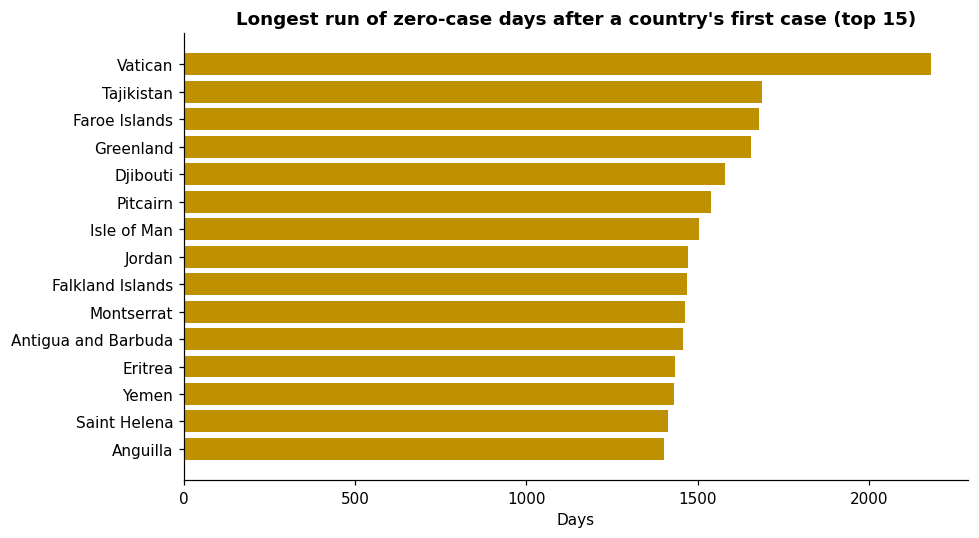

,longest_zero_run_days
entity,
Vatican,2180
Tajikistan,1689
Faroe Islands,1678
Greenland,1655
Djibouti,1579
Pitcairn,1538
Isle of Man,1503
Jordan,1472
Falkland Islands,1468


In [15]:
def longest_zero_run(g):
    g = g.sort_values("date")
    first = g.loc[g.weekly > 0, "date"].min()
    g = g[g.date >= first] if pd.notna(first) else g.iloc[0:0]
    if g.empty:
        return 0
    is_zero = (g.weekly == 0).astype(int).values
    best = cur = 0
    for z in is_zero:
        cur = cur + 1 if z else 0
        best = max(best, cur)
    return best

zero_runs = countries.groupby("entity").apply(longest_zero_run).rename("longest_zero_run_days")
top_zero = zero_runs.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_zero.index[::-1], top_zero.values[::-1], color="#bf9000")
ax.set_title("Longest run of zero-case days after a country's first case (top 15)")
ax.set_xlabel("Days")
plt.tight_layout(); plt.savefig(FIG + "13_zero_runs.png"); plt.show()

top_zero.to_frame()


## 14. Are there sudden spikes that look like catch-up reporting?

I flag days where the daily average is more than five times the median of the previous 28 days, above 500 cases, and then falls back below half its value within a week. A real wave keeps climbing or plateaus. A backlog of cases added at once looks like a spike that drops straight back down. This test is a rough filter, and I still read individual examples before drawing conclusions.

Flagged spike days: 195
Countries with flagged spikes: 31


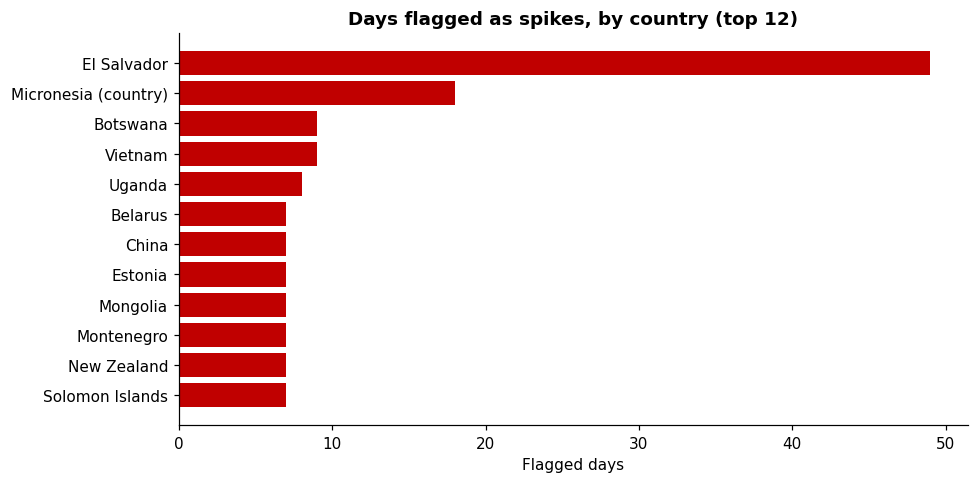

In [16]:
rows = []
for c, g in countries.sort_values("date").groupby("entity"):
    s_c = g.set_index("date")["daily_avg"]
    med = s_c.shift(1).rolling(28, min_periods=14).median()
    later = s_c.shift(-7)
    flag = s_c[(s_c > 5 * med) & (s_c > 500) & (later < 0.5 * s_c)]
    for d, v in flag.items():
        rows.append({"country": c, "date": d.date(), "daily_avg": round(v), "prior_28d_median": round(med[d])})
spikes = pd.DataFrame(rows)
print("Flagged spike days:", len(spikes))
print("Countries with flagged spikes:", spikes["country"].nunique() if len(spikes) else 0)

if len(spikes):
    per_c = spikes["country"].value_counts().head(12)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(per_c.index[::-1], per_c.values[::-1], color="#c00000")
    ax.set_title("Days flagged as spikes, by country (top 12)")
    ax.set_xlabel("Flagged days")
    plt.tight_layout(); plt.savefig(FIG + "14_spikes.png"); plt.show()
    spikes.head(10)


## 15. Do countries' waves move together?

I compare daily averages across 12 countries during 2022 and 2023, a period with many overlapping waves. High correlations suggest shared variant timing, while low ones point to national differences in timing or reporting.

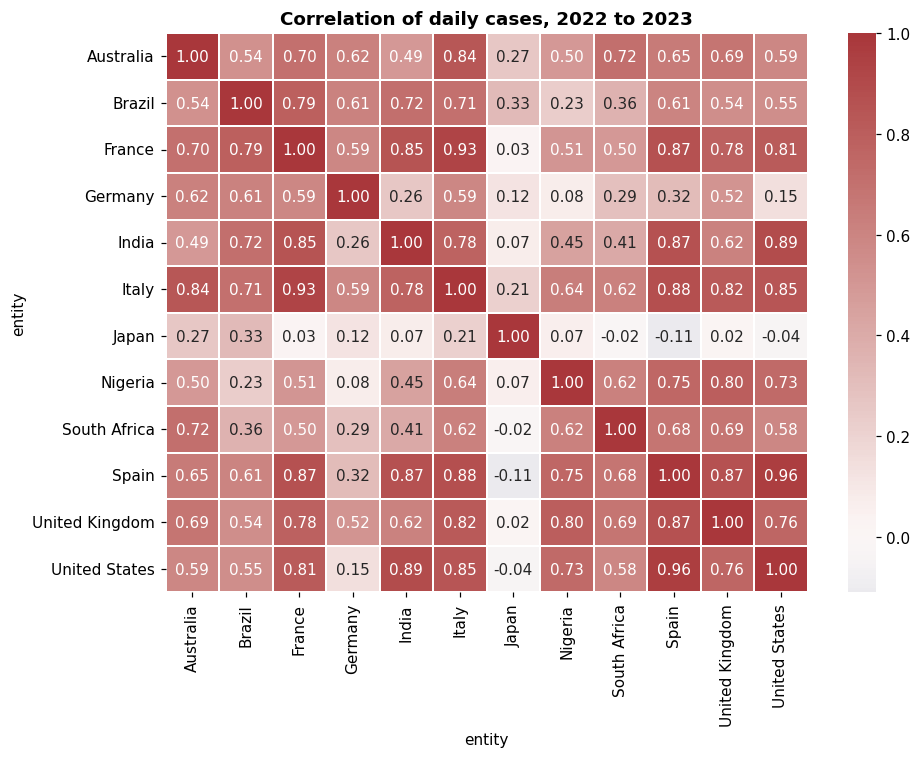

In [17]:
sel = ["United States", "United Kingdom", "France", "Germany", "Italy", "Spain", "Brazil",
       "India", "South Africa", "Nigeria", "Japan", "Australia"]
piv = (countries[countries.entity.isin(sel) & countries.date.between("2022-01-01", "2023-12-31")]
       .pivot(index="date", columns="entity", values="daily_avg"))
corr = piv.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", linewidths=0.3, ax=ax)
ax.set_title("Correlation of daily cases, 2022 to 2023")
plt.tight_layout(); plt.savefig(FIG + "15_correlation.png"); plt.show()


## 16. How do income groups differ in their case curves?

The file includes World Bank income groups as aggregates. I compare their daily averages and their share of total recorded cases.

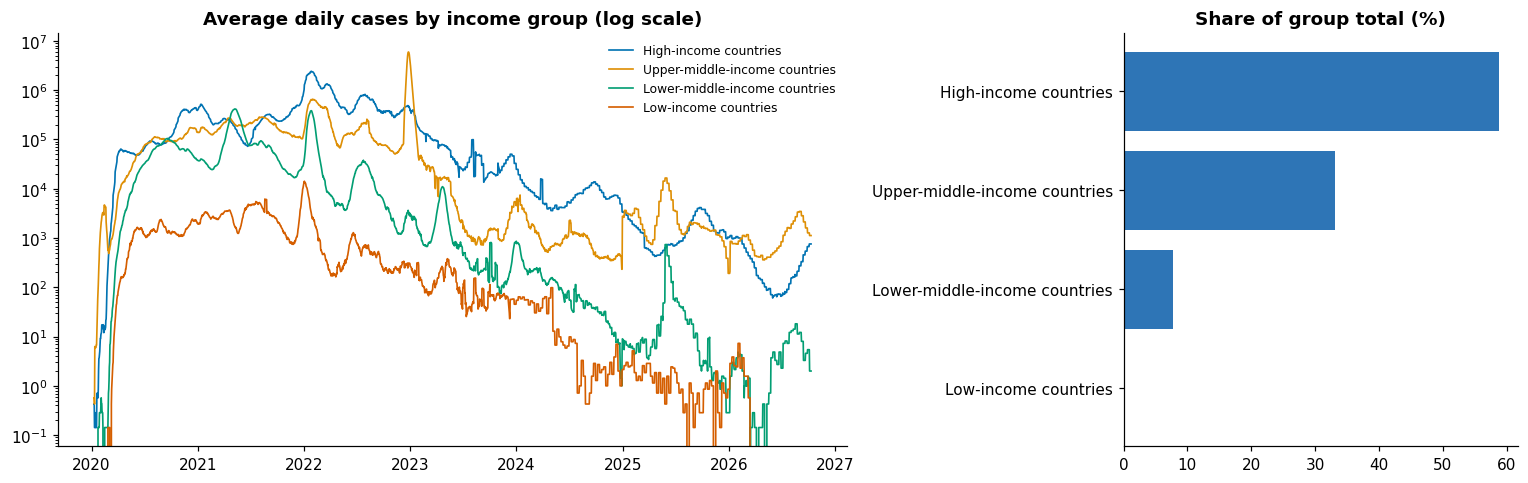

,share_pct
entity,
Low-income countries,0.2
Lower-middle-income countries,7.8
Upper-middle-income countries,33.1
High-income countries,58.8


In [18]:
groups = ["High-income countries", "Upper-middle-income countries",
          "Lower-middle-income countries", "Low-income countries"]
gp = w[w["entity"].isin(groups)].pivot(index="date", columns="entity", values="daily_avg")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for g in groups:
    a1.plot(gp.index, gp[g], label=g, linewidth=1.1)
a1.set_yscale("log")
a1.set_title("Average daily cases by income group (log scale)")
a1.legend(frameon=False, fontsize=8)

g_tot = w[w["entity"].isin(groups)].groupby("entity")["weekly"].sum() / 7
g_share = (g_tot / g_tot.sum() * 100).sort_values()
a2.barh(g_share.index, g_share.values, color="#2e75b6")
a2.set_title("Share of group total (%)")
plt.tight_layout(); plt.savefig(FIG + "16_income_groups.png"); plt.show()

g_share.round(1).to_frame("share_pct")


## 17. What does the most recent year look like?

I zoom in on the last 12 months and show monthly totals for the world and for Nigeria. Nigeria's values are very small in recent years. Monthly totals make the few reported cases visible, where daily averages would round to zero.

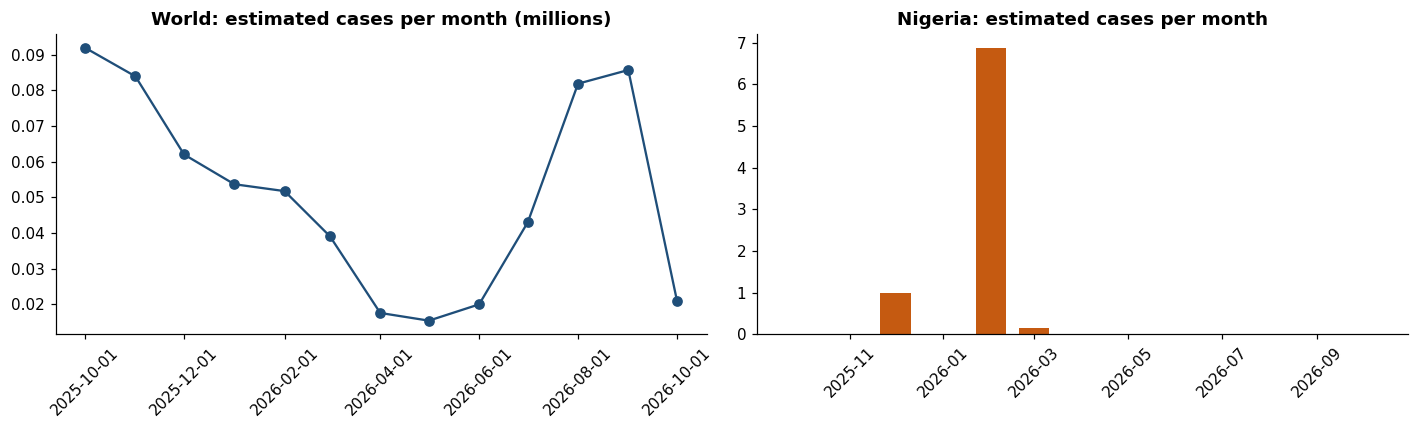

entity,Nigeria,World
date,,
2025-10-01,0,91887
2025-11-01,0,83887
2025-12-01,1,61996
2026-01-01,0,53667
2026-02-01,7,51736
2026-03-01,0,39068
2026-04-01,0,17598
2026-05-01,0,15441
2026-06-01,0,20010


In [19]:
last = pd.Timestamp(w["date"].max())
start = last - pd.DateOffset(months=12)
rec = w[w.date.between(start, last) & w.entity.isin(["World", "Nigeria"])].copy()
rec["cases"] = rec["weekly"] / 7
monthly = rec.groupby(["entity", pd.Grouper(key="date", freq="MS")])["cases"].sum().unstack(0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(monthly.index, monthly["World"] / 1e6, marker="o", color="#1f4e79")
a1.set_title("World: estimated cases per month (millions)")
a1.set_xticks(monthly.index[::2]); a1.tick_params(axis="x", rotation=45)
a2.bar(monthly.index, monthly["Nigeria"], width=20, color="#c55a11")
a2.set_title("Nigeria: estimated cases per month")
a2.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIG + "17_recent_year.png"); plt.show()

monthly.round(0).astype("int64")


## 18. How spread out were countries' daily averages each year?

For each year, I compare the average daily case count of every country. A wide box means some countries were very high while others were low. The log scale keeps very large countries from hiding the rest. Continent and income membership are not in this file, so this is a year-by-year comparison across all countries.

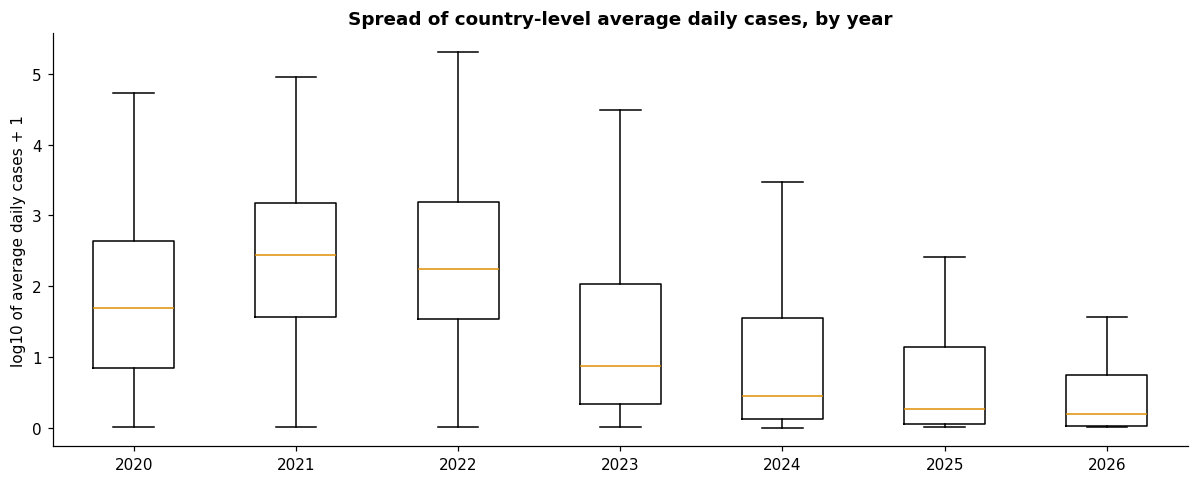

,median_country_daily_avg
year,
2020,48.0
2021,277.0
2022,173.0
2023,6.0
2024,2.0
2025,1.0
2026,1.0


In [20]:
yr = (countries.assign(year=countries.date.dt.year)
      .groupby(["year", "entity"])["daily_avg"].mean()
      .reset_index())
yr = yr[yr.daily_avg > 0]

fig, ax = plt.subplots(figsize=(11, 4.5))
years = sorted(yr.year.unique())
ax.boxplot([np.log10(yr[yr.year == y].daily_avg.values + 1) for y in years],
           tick_labels=[str(y) for y in years], showfliers=False)
ax.set_ylabel("log10 of average daily cases + 1")
ax.set_title("Spread of country-level average daily cases, by year")
plt.tight_layout(); plt.savefig(FIG + "18_distribution_by_year.png"); plt.show()

yr.groupby("year")["daily_avg"].median().round(0).to_frame("median_country_daily_avg")


## 19. Summary of findings

**What the data shows**

- The global daily average peaked on 26 December 2022, at about 6.4 million cases per day. That peak is driven by China's late-2022 wave in this file.
- About 56 percent of the estimated 779 million recorded cases fall in 2022. Recorded cases fall sharply after 2022. This file cannot tell whether that reflects lower infection, reduced testing, or both.
- The United States, China and India have the largest estimated totals. China's total is dominated by its late-2022 wave, which is a good example of why totals need caution.
- Nigeria's estimated total is about 267,000, and its highest daily average was about 1,950 cases in late December 2021. That timing matches the Omicron wave that reached southern Africa in late 2021. South Africa's peak came in the same weeks, at about 23,400 cases per day.
- Africa's share of recorded cases was about 3 to 3.5 percent in 2020 and 2021, and fell below 1 percent from 2022. This file cannot separate a real fall in infection from reduced testing and reporting.
- Reporting degrades over time. 147 countries have no non-zero count in 2026, and the United States' last non-zero value in this file is in May 2023.

**What the data cannot show**

- Recorded cases depend on testing, reporting rules and lab capacity. They are not a measure of infection.
- Without population data, these results cannot be compared per person. Adding the OWID population file would fix this.
- The file does not name variants, so any link between a peak and a variant is an inference from timing, not a finding of this analysis.

**Suggested next steps**

Pair this file with the ICU occupancy dataset to test whether case peaks lead hospital pressure. Add a population file to compare countries per 100,000 people.